In [1]:
import numpy as np
import qiskit
import openfermion
import pyscf

 H<sub>2</sub> molecule in minimal basis

## Molecular model and Hartree-Fock reference

We use H$_2$ at a fixed bond length of 0.74 Angstrom and the minimal STO-3G basis. A restricted Hartree-Fock (RHF) calculation assumes that the alpha and beta electrons occupy the same spatial molecular orbitals. The self-consistent-field procedure solves the mean-field problem and provides the molecular-orbital coefficient matrix $C$ used below.

The Hartree-Fock energy is a useful reference, but it is not generally the exact electronic energy because electron correlation is approximated.

In [2]:
# H2 molecule
from pyscf import gto, scf

# Build molecule
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 0.74)]],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.11675930739643


np.float64(-1.1167593073964255)

Extract electronic integrals

## Molecular-orbital integrals

The one-electron core Hamiltonian contains kinetic energy and electron-nuclear attraction. It is transformed from the atomic-orbital basis to the molecular-orbital basis as

$$h_{pq} = \sum_{\mu\nu} C_{\mu p} h_{\mu\nu} C_{\nu q}. $$

The four-index electron-repulsion integrals describe the Coulomb interaction between two electrons. The transpose at the end puts the PySCF result into the index convention used when constructing the OpenFermion Hamiltonian. `e_nuc` is the constant nuclear-nuclear repulsion energy.

In [3]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)

[[-1.25330979e+00  3.71049551e-17]
 [ 1.34841040e-17 -4.75068849e-01]]
[[[[ 6.74755927e-01 -3.75785642e-17]
   [-5.45047948e-17  1.81210462e-01]]

  [[-5.45047948e-17  1.81210462e-01]
   [ 6.63711401e-01  4.06319362e-16]]]


 [[[-3.75785642e-17  6.63711401e-01]
   [ 1.81210462e-01  5.57982113e-16]]

  [[ 1.81210462e-01  5.57982113e-16]
   [ 4.06319362e-16  6.97651504e-01]]]]


In [4]:
e_nuc = mf.energy_nuc()
e_nuc

np.float64(0.7151043390810812)

## Determinants and spin orbitals

Two spatial orbitals give four spin orbitals. This notebook uses the interleaved ordering $(0_\alpha,0_\beta,1_\alpha,1_\beta)$. A string such as `0^ 1^` denotes the determinant $a_0^\dagger a_1^\dagger |\mathrm{vac}\rangle$. The four determinants below span the two-electron, $M_S=0$ subspace used later as a compact two-qubit model.

In [5]:
from openfermion import FermionOperator

D0 = FermionOperator('0^ 1^')
D1 = FermionOperator('0^ 3^')
D2 = FermionOperator('1^ 2^')
D3 = FermionOperator('2^ 3^')

## Second-quantized electronic Hamiltonian

The code builds the electronic Hamiltonian in second quantization,

$$H = E_{\mathrm{nuc}} + \sum_{pq} h_{pq} a_p^\dagger a_q + \frac{1}{2}\sum_{pqrs} h_{pqrs} a_p^\dagger a_q^\dagger a_r a_s. $$

Each spatial-orbital contribution is expanded over alpha and beta spin orbitals. `FermionOperator` keeps the creation and annihilation operators symbolic, so the resulting expression can later be converted either to a matrix or to qubit operators.

In [6]:
H = FermionOperator('') * e_nuc

for i in range(2):
    for j in range(2):
        # α
        H += h1_mo[i, j] * FermionOperator('{}^ {}'.format(2*i, 2*j))
        # β
        H += h1_mo[i, j] * FermionOperator('{}^ {}'.format(2*i+1, 2*j+1))

# Two-electron part
for p in range(2):
    for q in range(2):
        for r in range(2):
            for s in range(2):

                value = 0.5 * eri_mo[p, q, r, s]
                # αα

                H += value * FermionOperator( f'{2*p}^ {2*q}^ {2*r} {2*s}')
                # αβ
                H += value * FermionOperator(f'{2*p}^ {2*q+1}^ {2*r+1} {2*s}')
                # βα
                H += value * FermionOperator(f'{2*p+1}^ {2*q}^ {2*r} {2*s+1}')
                # ββ
                H += value * FermionOperator(f'{2*p+1}^ {2*q+1}^ {2*r+1} {2*s+1}')
H

0.7151043390810812 [] +
-1.2533097866459773 [0^ 0] +
0.3373779634072242 [0^ 0^ 0 0] +
0.09060523100759837 [0^ 0^ 2 2] +
0.3373779634072242 [0^ 1^ 1 0] +
0.09060523100759837 [0^ 1^ 3 2] +
0.09060523100759837 [0^ 2^ 0 2] +
0.3318557006754066 [0^ 2^ 2 0] +
0.09060523100759837 [0^ 3^ 1 2] +
0.3318557006754066 [0^ 3^ 3 0] +
0.3373779634072242 [1^ 0^ 0 1] +
0.09060523100759837 [1^ 0^ 2 3] +
-1.2533097866459773 [1^ 1] +
0.3373779634072242 [1^ 1^ 1 1] +
0.09060523100759837 [1^ 1^ 3 3] +
0.09060523100759837 [1^ 2^ 0 3] +
0.3318557006754066 [1^ 2^ 2 1] +
0.09060523100759837 [1^ 3^ 1 3] +
0.3318557006754066 [1^ 3^ 3 1] +
0.3318557006754067 [2^ 0^ 0 2] +
0.09060523100759837 [2^ 0^ 2 0] +
0.3318557006754067 [2^ 1^ 1 2] +
0.09060523100759837 [2^ 1^ 3 0] +
-0.4750688487721783 [2^ 2] +
0.09060523100759837 [2^ 2^ 0 0] +
0.3488257522452306 [2^ 2^ 2 2] +
0.09060523100759837 [2^ 3^ 1 0] +
0.3488257522452306 [2^ 3^ 3 2] +
0.3318557006754067 [3^ 0^ 0 3] +
0.09060523100759837 [3^ 0^ 2 1] +
0.3318557006754067

## Exact spectrum in Fock space

`get_sparse_operator` represents the fermionic Hamiltonian on all $2^4=16$ occupation-number states. Diagonalizing this matrix produces states with different electron numbers, so the next cell evaluates the number operator

$$\hat N = \sum_p a_p^\dagger a_p$$

for every eigenvector. The two-electron eigenvalues can be compared with the full configuration-interaction (FCI) calculation from PySCF.

In [7]:
from openfermion import get_sparse_operator

H_sparse = get_sparse_operator(H)
print(H_sparse)


<Compressed Sparse Column sparse matrix of dtype 'complex128'
	with 20 stored elements and shape (16, 16)>
  Coords	Values
  (0, 0)	(0.7151043390810812+0j)
  (1, 1)	(0.24003549030890287+0j)
  (2, 2)	(0.24003549030890287+0j)
  (3, 3)	(0.46261814602718576+0j)
  (12, 3)	(0.18121046201519675+0j)
  (4, 4)	(-0.5382054475648961+0j)
  (5, 5)	(-0.5307733570014579+0j)
  (6, 6)	(-0.34956289498626114+0j)
  (9, 6)	(-0.18121046201519675+0j)
  (7, 7)	(0.3555207000676382+0j)
  (8, 8)	(-0.5382054475648961+0j)
  (6, 9)	(-0.18121046201519675+0j)
  (9, 9)	(-0.34956289498626114+0j)
  (10, 10)	(-0.5307733570014579+0j)
  (11, 11)	(0.3555207000676382+0j)
  (3, 12)	(0.18121046201519675+0j)
  (12, 12)	(-1.1167593073964248+0j)
  (13, 13)	(-0.44561581548217316+0j)
  (14, 14)	(-0.44561581548217316+0j)
  (15, 15)	(0.9231791809225397+0j)


In [8]:
import numpy as np

np.linalg.eigvals(H_sparse.toarray().real)

array([-0.53077336, -0.16835243, -1.13728383,  0.48314267,  0.71510434,
        0.24003549,  0.24003549, -0.53820545, -0.53077336,  0.3555207 ,
       -0.53820545, -0.53077336,  0.3555207 , -0.44561582, -0.44561582,
        0.92317918])

In [9]:
from openfermion import number_operator, get_sparse_operator

N = number_operator(4)

N_sparse = get_sparse_operator(N)
eigvals, eigvecs = np.linalg.eigh(H_sparse.toarray())

for E, psi in zip(eigvals, eigvecs.T):
    n = np.real(psi.conj() @ (N_sparse @ psi))
    print('{:12.8f} {:4.1f}'.format(E, n))


 -1.13728383  2.0
 -0.53820545  1.0
 -0.53820545  1.0
 -0.53077336  2.0
 -0.53077336  2.0
 -0.53077336  2.0
 -0.44561582  3.0
 -0.44561582  3.0
 -0.16835243  2.0
  0.24003549  1.0
  0.24003549  1.0
  0.35552070  3.0
  0.35552070  3.0
  0.48314267  2.0
  0.71510434  0.0
  0.92317918  4.0


In [10]:
from pyscf import fci

cisolver = fci.FCI(mol, mf.mo_coeff)
cisolver.nroots = 4
energy, ci = cisolver.kernel()
print("FCI energy:", energy)


FCI energy: [-1.13728383 -0.53077336 -0.16835243  0.48314267]


\begin{aligned}
H_{IJ}=\langle D_I|H|D_J\rangle
\end{aligned}

## Projecting to a four-dimensional active space

Instead of retaining every Fock state, we evaluate $H_{IJ}$ between the four selected determinants. `hermitian_conjugated(b1) * H * b2` forms the operator expression for $\langle D_I|H|D_J\rangle$; normal ordering exposes its scalar vacuum expectation value. The resulting $4 \times 4$ matrix has the same two-electron eigenvalues as the selected determinant subspace.

In [11]:
from openfermion import hermitian_conjugated, normal_ordered

H_matrix = np.zeros((4, 4))
basis = [D0, D1, D2, D3]
for i, b1 in enumerate(basis):
    for j, b2 in enumerate(basis):

        term = normal_ordered(hermitian_conjugated(b1) * H * b2)
        H_matrix[i, j] = term.terms.get((), 0.0)
H_matrix

array([[-1.11675931,  0.        ,  0.        ,  0.18121046],
       [ 0.        , -0.34956289, -0.18121046,  0.        ],
       [ 0.        , -0.18121046, -0.34956289,  0.        ],
       [ 0.18121046,  0.        ,  0.        ,  0.46261815]])

In [12]:
np.linalg.eigvals(H_matrix)

array([-1.13728383,  0.48314267, -0.16835243, -0.53077336])

## Encoding the active-space Hamiltonian on two qubits

A four-dimensional Hilbert space can be encoded in two qubits. The code writes matrix units $|i\rangle\langle j|$ in the Pauli basis, using

$$|0\rangle\langle0|=\frac{I+Z}{2},\quad |1\rangle\langle1|=\frac{I-Z}{2},\quad |0\rangle\langle1|=\frac{X+iY}{2}. $$

Tensor products of these one-qubit operators reconstruct each matrix element of $H_{IJ}$. The following diagonalization verifies that the Pauli Hamiltonian has the same spectrum as `H_matrix`.

In [13]:
from openfermion import QubitOperator

I = QubitOperator(())

# qubit 0
P00_q0 = 0.5 * (I + QubitOperator("Z0"))
P01_q0 = 0.5 * (QubitOperator("X0") + 1j * QubitOperator("Y0"))
P10_q0 = 0.5 * (QubitOperator("X0") - 1j * QubitOperator("Y0"))
P11_q0 = 0.5 * (I - QubitOperator("Z0"))

basis_q0 = [P00_q0, P01_q0, P10_q0, P11_q0]


# qubit 1
P00_q1 = 0.5 * (I + QubitOperator("Z1"))
P01_q1 = 0.5 * (QubitOperator("X1") + 1j * QubitOperator("Y1"))
P10_q1 = 0.5 * (QubitOperator("X1") - 1j * QubitOperator("Y1"))
P11_q1 = 0.5 * (I - QubitOperator("Z1"))

basis_q1 = [P00_q1, P01_q1, P10_q1, P11_q1]


# correspondence basis order to matrix order (|0><0| x |1><0| = |01><00|)
def matrix_index(i, j):
    bra0, ket0 = divmod(i, 2)
    bra1, ket1 = divmod(j, 2)
    bra = 2 * bra0 + bra1
    ket = 2 * ket0 + ket1
    return bra, ket

# Build Hamiltonian
H_qubit = QubitOperator(())*0
for i, q1 in enumerate(basis_q0):
    for j, q2 in enumerate(basis_q1):
        bra, ket = matrix_index(i, j)
        H_qubit += q1*q2 * H_matrix[bra, ket]

print(H_qubit)


-0.33831673783544036 [] +
(-0.18121046201519675+0j) [Y0 Y1] +
-0.39484436335590267 [Z0] +
0.011246157150820807 [Z0 Z1] +
-0.39484436335590267 [Z1]


In [14]:
from openfermion import get_sparse_operator
H_sparse = get_sparse_operator(H_qubit)
np.linalg.eigvals(H_sparse.toarray()).real


array([-1.13728383,  0.48314267, -0.16835243, -0.53077336])

## Variational quantum eigensolver (VQE) ansatz

The two-qubit circuit prepares a trial state $|\psi(\boldsymbol{\theta})\rangle$. Independent $R_y$ rotations create adjustable single-qubit amplitudes, and the CNOT creates entanglement. Binding numerical values to the four parameters produces one concrete circuit whose computational-basis measurement probabilities can be sampled.

VQE minimizes the variational energy

$$E(\boldsymbol{\theta})=\langle\psi(\boldsymbol{\theta})|H_{\mathrm{qubit}}|\psi(\boldsymbol{\theta})\rangle. $$

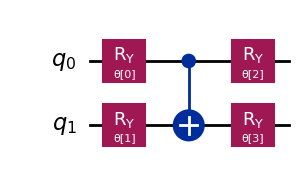

In [15]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

# Define the variational parameters
theta = ParameterVector("θ", 4)

# Build the ansatz
qc = QuantumCircuit(2)

qc.ry(theta[0], 0)
qc.ry(theta[1], 1)

qc.cx(0, 1)

qc.ry(theta[2], 0)
qc.ry(theta[3], 1)

qc.draw('mpl')
#qc.draw()

In [16]:
import numpy as np

params = np.random.rand(4)
print(params)

qc_bound = qc.assign_parameters(params)


[0.54573768 0.61787623 0.15339842 0.64401095]


In [17]:
from qiskit.primitives import StatevectorSampler

# Add measurements
qc_meas = qc_bound.copy()
qc_meas.measure_all()

# Sample
sampler = StatevectorSampler()

result = sampler.run([qc_meas], shots=10000).result()
counts = result[0].data.meas.get_counts()

print(counts)

{'00': 6064, '10': 2926, '11': 970, '01': 40}


In [18]:
# test ansatz
#qc_bound = QuantumCircuit(2)

#qc_bound.x(0)
#qc_bound.x(1)
#print(qc_bound)

## Measuring Pauli terms and optimizing the energy

The qubit Hamiltonian is a sum $H_{\mathrm{qubit}}=\sum_k c_k P_k$ of Pauli strings. Each term is measured separately after rotating its qubits into the computational ($Z$) basis: a Hadamard maps an $X$ measurement to a $Z$ measurement, while the $R_x(\pi/2)$ rotation used here maps the chosen $Y$ convention to $Z$. For a measured bit string $b$, the Pauli eigenvalue is its parity, $(-1)^{\sum_{q\in P_k} b_q}$.

The estimator is $\widehat E=\sum_k c_k\widehat{\langle P_k\rangle}$. `cost_function` recomputes this estimator for a proposed parameter vector, and COBYLA changes the parameters to lower it. Because measurements use a finite number of shots, the displayed objective is a statistical estimate of the exact expectation value.

In [19]:
energy = 0.0
for op, coeff in H_qubit.terms.items():

    qc_meas = qc_bound.copy()

    # set measurement basis
    for qi, pauli in op:
        if pauli == "X":
            qc_meas.h(qi)
        if pauli == "Y":
            qc_meas.rx(np.pi / 2, qi)
            #qc_meas.sdg(qi)
            #qc_meas.h(qi)

    qc_meas.measure_all()

    # Sample
    sampler = StatevectorSampler()

    result = sampler.run([qc_meas], shots=100000).result()
    counts = result[0].data.meas.get_counts()

    shots = sum(counts.values())

    for bitstring, count in counts.items():

        parity = 1

        for qi, pauli in op:
            if bitstring[::-1][qi] == "1":
                parity *= -1

        energy += parity * count / shots * coeff


print('Circuit energy', energy.real)

Circuit energy -0.6562633210829436


In [20]:
def cost_function(params):
    energy = 0.0
    for op, coeff in H_qubit.terms.items():

        qc_bound = qc.assign_parameters(params)

        qc_meas = qc_bound.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=100000).result()
        counts = result[0].data.meas.get_counts()

        shots = sum(counts.values())

        for bitstring, count in counts.items():

            parity = 1

            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real


In [21]:
import numpy as np
from scipy.optimize import minimize

# Initial parameters
x0 = np.random.rand(4)

# Optimization
result = minimize(
    cost_function,
    x0,
    method="COBYLA",
    options={"maxiter": 200,
             "disp": True,
             "rhobeg": 0.5,
             "tol": 1e-6,
    },
)

print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)

Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 64   Least value of F = -1.1380954838113442
The corresponding X is:
[-0.23597279  0.18269941 -0.01057611 -0.1569794 ]

Optimal parameters: [-0.23597279  0.18269941 -0.01057611 -0.1569794 ]
Minimum energy: -1.1380954838113442
